# 📈 Previsão de Preços de Ações com PyTorch (LSTM)

Projeto de estudo baseado no tutorial *"Stock Price Prediction in Python with PyTorch - Full Tutorial"*. Uma rede LSTM aprende a prever o preço de fechamento do dia seguinte a partir dos 29 dias anteriores.

> ⚠️ **Aviso:** projeto exclusivamente educacional. Nada aqui é recomendação financeira, e este código não deve ser usado para tentar prever preços de ações de verdade.

## 📦 Importação das Bibliotecas e Configuração

Importação das bibliotecas usadas no projeto e escolha do dispositivo (GPU ou CPU) onde o modelo será executado.

In [36]:
# Desativa os avisos (warnings) para deixar as saídas mais limpas
import warnings
warnings.filterwarnings('ignore', category=Warning)

# Manipulação de dados, download das cotações e gráficos
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

# PyTorch: tensores, camadas da rede neural e otimizadores
import torch
import torch.nn as nn
import torch.optim as optim

# Scikit-learn: normalização dos dados e métrica de avaliação
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error

In [37]:
# Define o dispositivo de execução: GPU (cuda) se disponível, senão CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

## 📥 Coleta dos Dados

Download do histórico de cotações pelo Yahoo Finance e visualização inicial do preço de fechamento.

In [91]:
# Baixa o histórico diário de cotações da ação escolhida desde 01/01/2020
ticker = 'MSFT'
df = yf.download(tickers=ticker, start='2020-01-01')

[*********************100%***********************]  1 of 1 completed


In [92]:
# Exibe o DataFrame com as cotações baixadas
df

Price,Close,High,Low,Open,Volume
Ticker,MSFT,MSFT,MSFT,MSFT,MSFT
Date,,,,,
2020-01-02,151.544250,151.648036,149.383652,149.808222,22622100
2020-01-03,149.657318,150.912169,149.128963,149.374281,21116200
2020-01-06,150.044128,150.110180,147.666515,148.204315,20813700
2020-01-07,148.676025,150.647928,148.430722,150.317713,21634100
2020-01-08,151.044220,151.714108,149.025140,149.949762,27746500
...,...,...,...,...,...
2026-10-26,532.599976,533.250000,521.690002,527.400024,19021000
2026-10-27,531.330017,534.700012,528.330017,532.349976,19532300


<Axes: xlabel='Date'>

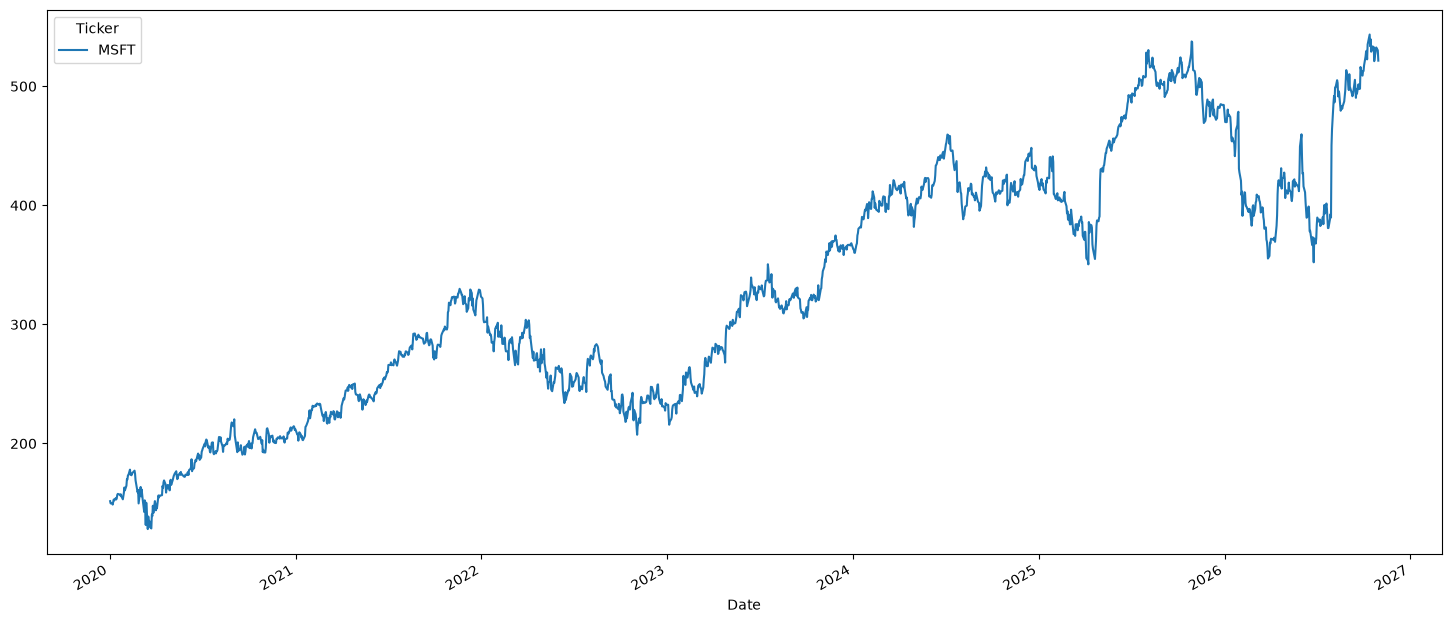

In [93]:
# Plota a evolução do preço de fechamento ao longo do tempo
df.Close.plot(figsize=(18, 8))

## ⚖️ Pré-processamento: Normalização

Padronização do preço de fechamento com `StandardScaler`, o que ajuda a rede neural a convergir durante o treino.

In [94]:
# Normaliza o preço de fechamento (média 0 e desvio padrão 1)
scaler = StandardScaler()

df['Close'] = scaler.fit_transform(df['Close'])

In [95]:
# Exibe o preço de fechamento após a normalização
df['Close']

Ticker,MSFT
Date,
2020-01-02,-1.704617
2020-01-03,-1.722715
2020-01-06,-1.719005
2020-01-07,-1.732127
2020-01-08,-1.709413
...,...
2026-10-26,1.950162
2026-10-27,1.937981
2026-10-28,1.934912


## 🪟 Criação das Sequências (Janelas Deslizantes)

Divisão da série temporal em janelas de `seq_length` dias consecutivos, que serão os exemplos usados pelo modelo.

In [96]:
# Cria janelas deslizantes de 30 dias consecutivos, avançando um dia por vez
# Formato final: (número de janelas, seq_length, 1)
seq_length = 30
data = []

for i in range(len(df) - seq_length):
    data.append(df.Close[i:i+seq_length])

data = np.array(data)

In [97]:
# Exibe o array de janelas gerado
data

array([[[-1.70461682],
        [-1.72271476],
        [-1.71900478],
        ...,
        [-1.48906394],
        [-1.48662019],
        [-1.4956696 ]],

       [[-1.72271476],
        [-1.71900478],
        [-1.73212652],
        ...,
        [-1.48662019],
        [-1.4956696 ],
        [-1.48082883]],

       [[-1.71900478],
        [-1.73212652],
        [-1.70941271],
        ...,
        [-1.4956696 ],
        [-1.48082883],
        [-1.46381609]],

       ...,

       [[ 1.54445452],
        [ 1.61590902],
        [ 1.57783197],
        ...,
        [ 1.87256941],
        [ 1.95016183],
        [ 1.93798141]],

       [[ 1.61590902],
        [ 1.57783197],
        [ 1.65293088],
        ...,
        [ 1.95016183],
        [ 1.93798141],
        [ 1.93491216]],

       [[ 1.57783197],
        [ 1.65293088],
        [ 1.61830681],
        ...,
        [ 1.93798141],
        [ 1.93491216],
        [ 1.92656787]]], shape=(1687, 30, 1))

## ✂️ Separação entre Treino e Teste

Separação cronológica das janelas (80% treino, 20% teste) e divisão de cada janela em entrada (**X**) e alvo (**y**).

In [98]:
# Define o tamanho do conjunto de treino (80% das janelas, em ordem cronológica)
train_size = int(0.8 * len(data))

# Treino: X recebe os 29 primeiros dias de cada janela e y recebe o último dia (alvo)
X_train = torch.from_numpy(data[:train_size, :-1, :]).type(torch.Tensor).to(device)
y_train = torch.from_numpy(data[:train_size, -1, :]).type(torch.Tensor).to(device)

# Teste: mesma separação, aplicada aos 20% finais das janelas
X_test = torch.from_numpy(data[train_size:, :-1, :]).type(torch.Tensor).to(device)
y_test = torch.from_numpy(data[train_size:, -1, :]).type(torch.Tensor).to(device)

## 🧠 Construção do Modelo LSTM

Definição da arquitetura da rede, da função de perda e do otimizador.

In [99]:
# Define a arquitetura do modelo: camadas LSTM seguidas de uma camada linear
class PredictionModel(nn.Module):

    def __init__(self, input_dim, hidden_dim, num_layers, output_dim):
        super(PredictionModel, self).__init__()

        self.num_layers = num_layers
        self.hidden_dim = hidden_dim

        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim, device=device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim, device=device)

        out, (hn, cn) = self.lstm(x, (h0.detach(), c0.detach()))
        out = self.fc(out[:, -1, :])

        return out

In [100]:
# Instancia o modelo: 1 feature de entrada, 32 neurônios ocultos, 2 camadas LSTM e 1 saída
model = PredictionModel(input_dim=1, hidden_dim=32, num_layers=2, output_dim=1).to(device)

In [101]:
# Define a função de perda: erro quadrático médio (MSE)
criterion = nn.MSELoss()

# Define o otimizador Adam com taxa de aprendizado de 0.01
optimizer = optim.Adam(model.parameters(), lr=0.01)

## 🏋️ Treinamento do Modelo

Ajuste dos pesos da rede ao longo das épocas, acompanhando a evolução da perda.

In [102]:
# Treina o modelo por 200 épocas, exibindo a perda a cada 25 épocas
num_epochs = 200

for i in range(num_epochs):
    y_train_pred = model(X_train)

    loss = criterion(y_train_pred, y_train)

    if i % 25 == 0:
        print(i, loss.item())

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

0 0.7405205965042114
25 0.008774110116064548
50 0.0050138323567807674
75 0.004107499960809946
100 0.0038174763321876526
125 0.003609337145462632
150 0.0034377973061054945
175 0.0032897084020078182


## 📊 Avaliação do Modelo

Geração das previsões no conjunto de teste, retorno dos valores para dólares e cálculo do RMSE.

In [103]:
# Coloca o modelo em modo de avaliação e gera as previsões para o conjunto de teste
model.eval()

y_test_pred = model(X_test)

# Desfaz a normalização para que previsões e valores reais voltem a ser preços em dólares
y_train_pred = scaler.inverse_transform(y_train_pred.detach().cpu().numpy())
y_train = scaler.inverse_transform(y_train.detach().cpu().numpy())
y_test_pred = scaler.inverse_transform(y_test_pred.detach().cpu().numpy())
y_test = scaler.inverse_transform(y_test.detach().cpu().numpy())

In [104]:
# Calcula o RMSE (raiz do erro quadrático médio) no conjunto de treino
train_rmse = root_mean_squared_error(y_train[:, 0], y_train_pred[:, 0])

# Calcula o RMSE no conjunto de teste
test_rmse = root_mean_squared_error(y_test[:, 0], y_test_pred[:, 0])

In [105]:
# Exibe o RMSE do treino (em dólares)
train_rmse

5.86361026763916

In [106]:
# Exibe o RMSE do teste (em dólares)
test_rmse

10.548580169677734

## 📉 Visualização dos Resultados

Comparação gráfica entre os preços reais e os previstos, junto com o erro de previsão ao longo do tempo.

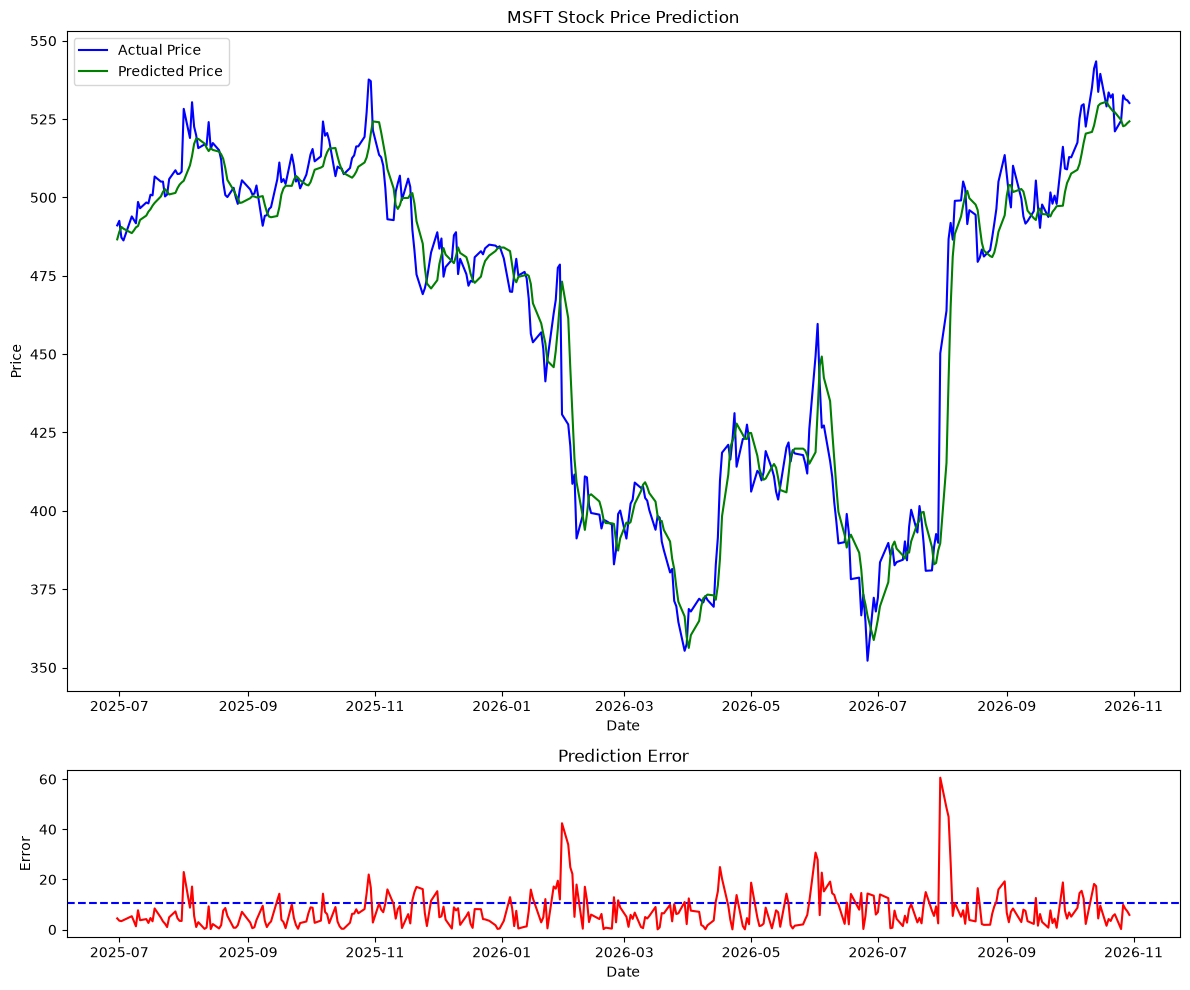

In [107]:
# Cria a figura com uma grade de 4 linhas para organizar os dois gráficos
fig = plt.figure(figsize=(12, 10))

gs = fig.add_gridspec(4, 1)

# Gráfico 1: preço real vs. preço previsto no período de teste
ax1 = fig.add_subplot(gs[:3, 0])
ax1.plot(df.iloc[-len(y_test):].index, y_test, color='blue', label='Actual Price')
ax1.plot(df.iloc[-len(y_test):].index, y_test_pred, color='green', label='Predicted Price')
ax1.legend()
plt.title(f"{ticker} Stock Price Prediction")
plt.xlabel('Date')
plt.ylabel('Price')

# Gráfico 2: erro absoluto da previsão por dia, com o RMSE como linha de referência
ax2 = fig.add_subplot(gs[3, 0])
ax2.axhline(test_rmse, color='blue', linestyle='--', label='RMSE')
ax2.plot(df[-len(y_test):].index, abs(y_test - y_test_pred), 'r', label='Prediction Error')
plt.title('Prediction Error')
plt.xlabel('Date')
plt.ylabel('Error')

# Ajusta o espaçamento e exibe a figura
plt.tight_layout()
plt.show()